# 04 – Review of the false alarms and revised labels

The false alarms of notebook 03 (patches ≥ 1 ha predicted hanging outside the mapped polygons) were checked
on SWISSIMAGE by the author with the same rules as the mapping (`data/raw/false_alarms_review.gpkg`):
each patch is judged `missed_hanging`, `model_error` or `unsure`, or redrawn as a new polygon in
`manual_mapping.gpkg` (`source = review`).

**Why two sets of labels.** The review only looked at places where the model said *hanging*. Corrections are
therefore all in the model's favour: scores computed with the revised labels are **optimistic**. The scores of
notebook 03, computed with the initial, blind mapping, stay the reference; the revised scores give an upper
bound, and the true skill lies in between.

- **initial labels**: polygons of the blind mapping (`source = initial`);
- **revised labels**: all polygons; reviewed patches judged hanging or unsure but not redrawn are **excluded**
  (neither hanging nor not hanging). The outlines of the patches, which come from the model, are never used
  as labels.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import rasterize
from sklearn.metrics import average_precision_score, precision_recall_curve

from classifier import EXCLUDED_VARIABLES, cross_validate, load_grids, make_forest, write_probability
from config import DEM_RES, PROCESSED, RAW
from relief import hillshade

FIG = ROOT / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

F, names, labels, profile = load_grids()
transform = profile["transform"]
glacier, block = labels["glacier"], labels["block"]
ice = glacier > 0
train = ice & (block > 0)

main_vars = [n for n in names if n not in EXCLUDED_VARIABLES]
X = F[[names.index(n) for n in main_vars]][:, train].T
b = block[train]
y_init = labels["hanging"][train]
y_rev = labels["hanging_revised"][train]
excl = labels["excluded"][train].astype(bool)

polygons = gpd.read_file(RAW / "manual_mapping.gpkg", layer="hanging_glaciers")
polygons["geometry"] = polygons.make_valid()
review = gpd.read_file(RAW / "false_alarms_review.gpkg", layer="false_alarms")
glaciers = gpd.read_file(PROCESSED / "sgi2023_zone.gpkg", layer="glaciers")

print(f"polygons: {(polygons['source'] == 'initial').sum()} initial, {(polygons['source'] == 'review').sum()} added after the review")
print(f"hanging pixels in the blocks: {y_init.sum():,} initial, {y_rev.sum():,} revised; "
      f"{excl.sum():,} pixels excluded from the revised labels")

polygons: 27 initial, 22 added after the review
hanging pixels in the blocks: 19,659 initial, 28,275 revised; 404 pixels excluded from the revised labels


## 1. What the false alarms were

A patch counts as *redrawn* when a polygon added after the review overlaps it.

In [2]:
redrawn_area = polygons[polygons["source"] == "review"].union_all()
review["outcome"] = np.where(review.intersects(redrawn_area), "redrawn as a polygon", review["verdict"].fillna("not reviewed"))
summary = review.groupby("outcome").agg(patches=("patch_id", "size"), area_ha=("area_ha", "sum"))
summary["share_of_patches"] = (summary["patches"] / len(review)).round(2)
confirmed = review["outcome"].isin(["missed_hanging", "redrawn as a polygon"])
print(f"{confirmed.sum()} of {len(review)} false-alarm patches (≥ 1 ha) are hanging glaciers missed by the mapping, "
      f"{(review['outcome'] == 'model_error').sum()} are model errors, {(review['outcome'] == 'unsure').sum()} unsure")
summary

25 of 28 false-alarm patches (≥ 1 ha) are hanging glaciers missed by the mapping, 2 are model errors, 1 unsure


,patches,area_ha,share_of_patches
outcome,,,
missed_hanging,1,1.0,0.04
model_error,2,7.0,0.07
redrawn as a polygon,24,64.4,0.86
unsure,1,3.0,0.04


## 2. Scores before and after the review

1. **initial**: out-of-fold predictions of notebook 03 (trained on the initial labels), scored against the initial labels;
2. **same predictions, revised labels**: the same predictions, scored against the revised labels (excluded pixels removed);
   the difference measures how much of the "error" was an error of the labels;
3. **retrained on revised labels**: leave-one-block-out cross-validation trained and scored on the revised labels.

Scores 2 and 3 are optimistic (see the introduction).

In [3]:
with rasterio.open(PROCESSED / f"oof_probability_{DEM_RES}m.tif") as src:
    p_init = src.read(1)[train]

keep = ~excl
p_rev, _ = cross_validate(X[keep], y_rev[keep], b[keep])

runs = {
    "initial (reference)": (y_init, p_init),
    "same predictions, revised labels": (y_rev[keep], p_init[keep]),
    "retrained on revised labels": (y_rev[keep], p_rev),
}
rows = []
for label, (yy, pp) in runs.items():
    rows.append({"run": label, "average_precision": average_precision_score(yy, pp),
                 "random_guess": yy.mean(), "precision_at_0.5": yy[pp >= 0.5].mean(),
                 "recall_at_0.5": np.mean(pp[yy == 1] >= 0.5)})
scores = pd.DataFrame(rows).set_index("run").round(3)
scores

,average_precision,random_guess,precision_at_0.5,recall_at_0.5
run,,,,
initial (reference),0.433,0.044,0.442,0.438
"same predictions, revised labels",0.689,0.064,0.734,0.495
retrained on revised labels,0.747,0.064,0.638,0.766


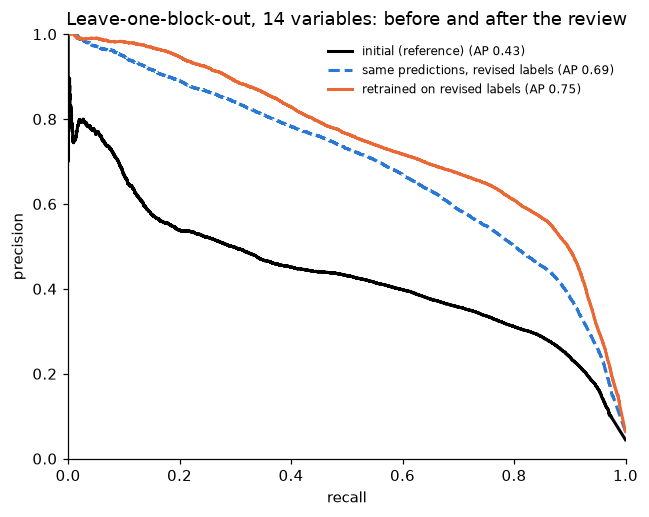

In [4]:
fig, ax = plt.subplots(figsize=(6, 4.8))
for (label, (yy, pp)), color, ls in zip(runs.items(), ["black", "#2a78d6", "#eb6834"], ["-", "--", "-"]):
    p, r, _ = precision_recall_curve(yy, pp)
    ax.plot(r, p, ls, color=color, lw=2, label=f"{label} (AP {average_precision_score(yy, pp):.2f})")
ax.set(xlabel="recall", ylabel="precision", xlim=(0, 1), ylim=(0, 1),
       title="Leave-one-block-out, 14 variables: before and after the review")
ax.legend(fontsize=8, frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "04_precision_recall_review.png", dpi=150)

## 3. Detection of each hanging glacier (revised polygons)

Same rule as notebook 03: a polygon is detected when at least 25 % of its labelled pixels have an
out-of-fold probability ≥ 0.5 (model retrained on the revised labels).

In [5]:
polygon_id = rasterize(zip(polygons.geometry, range(1, len(polygons) + 1)), out_shape=glacier.shape,
                       transform=transform, fill=0, dtype="int32")
polygon_id[~train] = 0
P_flat = np.full(glacier.size, np.nan)
P_flat[np.flatnonzero(train)[keep]] = p_rev     # out-of-fold probabilities (revised labels) on the flat grid

rows = []
for i, poly in polygons.iterrows():
    px = polygon_id.ravel() == i + 1
    if not px.any():
        continue
    g = np.bincount(glacier.ravel()[px]).argmax() - 1
    rows.append({"glacier": glaciers["name"].iloc[g], "glacier_area_km2": glaciers["area_km2"].iloc[g],
                 "source": poly["source"], "confidence": poly["confidence"], "pixels": px.sum(),
                 "detected_share": np.mean(P_flat[px] >= 0.5)})
det = pd.DataFrame(rows)
det["detected"] = det["detected_share"] >= 0.25
det["inside_large"] = det["glacier_area_km2"] > 1
print(f"{det['detected'].sum()} of {len(det)} polygons detected")
print(det.groupby(["source", "inside_large"])["detected"].agg(["sum", "size"]).rename(columns={"sum": "detected", "size": "polygons"}))

47 of 49 polygons detected
                      detected  polygons
source  inside_large                    
initial False               13        15
        True                12        12
review  False                3         3
        True                19        19


## 4. Map of the massif with the revised labels

A forest trained on the revised labels of the 4 blocks predicts every glacier pixel. This map is the input
of the candidate ranking.

In [6]:
final = make_forest().fit(X[keep], y_rev[keep])
prob = np.full(glacier.shape, np.nan, "float32")
prob[ice] = final.predict_proba(F[[names.index(n) for n in main_vars]][:, ice].T)[:, 1]
write_probability(prob, profile, PROCESSED / f"hanging_probability_revised_{DEM_RES}m.tif")

with rasterio.open(PROCESSED / f"hanging_probability_{DEM_RES}m.tif") as src:
    prob_init = src.read(1)
outside = ice & (block == 0)
for label, pm in [("initial labels", prob_init), ("revised labels", prob)]:
    print(f"{label}: {(pm[outside] >= 0.5).sum() * DEM_RES**2 / 1e6:.2f} km² predicted hanging outside the blocks "
          f"({np.mean(pm[outside] >= 0.5):.1%} of {outside.sum() * DEM_RES**2 / 1e6:.0f} km² of ice)")

initial labels: 3.43 km² predicted hanging outside the blocks (3.0% of 114 km² of ice)
revised labels: 5.85 km² predicted hanging outside the blocks (5.1% of 114 km² of ice)


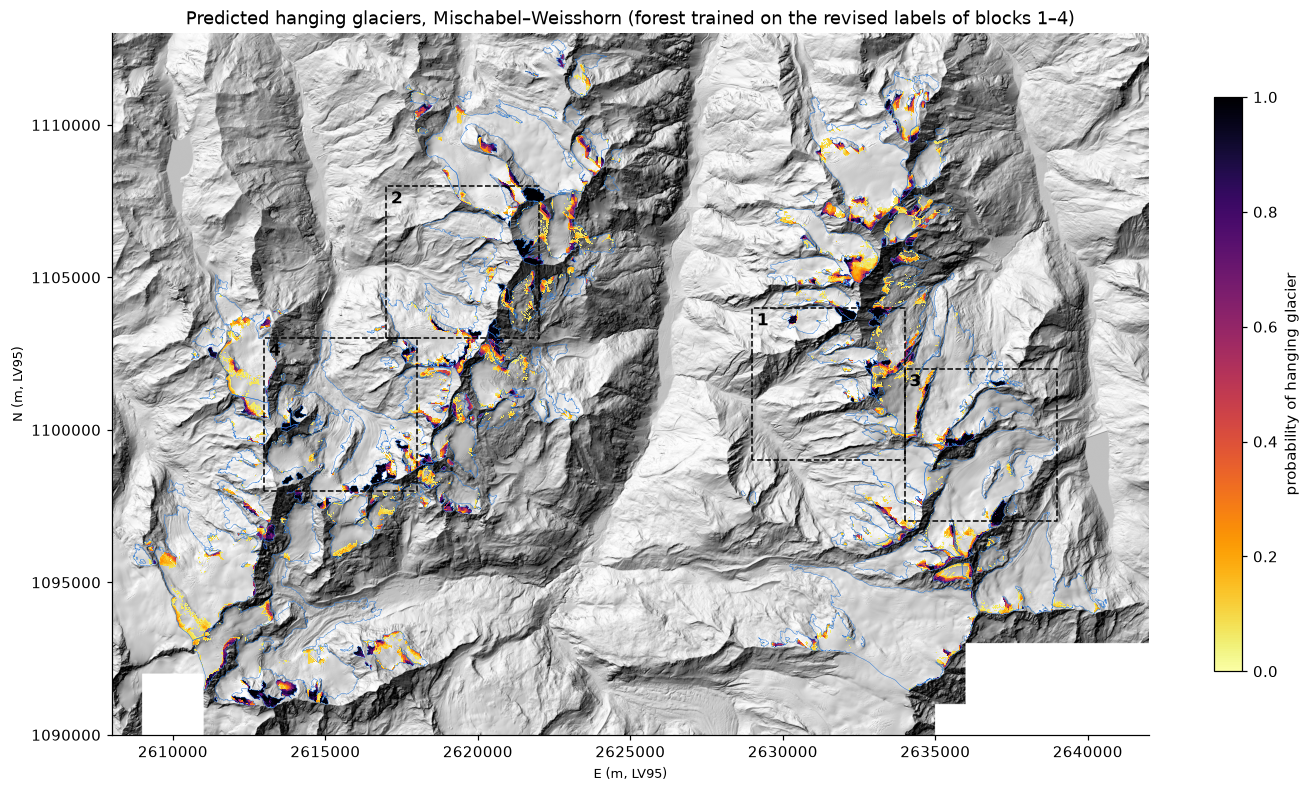

In [7]:
with rasterio.open(PROCESSED / f"dem_{DEM_RES}m.tif") as src:
    dem = src.read(1)
shade = hillshade(dem, DEM_RES)
blocks = gpd.read_file(RAW / "manual_mapping.gpkg", layer="blocks")
x0, y0 = transform * (0, dem.shape[0])
x1, y1 = transform * (dem.shape[1], 0)
ext = (x0, x1, y0, y1)

fig, ax = plt.subplots(figsize=(13, 9))
ax.imshow(shade, cmap="gray", extent=ext, vmin=-0.2, vmax=1)
im = ax.imshow(np.where(prob >= 0.05, prob, np.nan), cmap="inferno_r", vmin=0, vmax=1, extent=ext,
               interpolation="nearest")
glaciers.boundary.plot(ax=ax, color="#2a78d6", lw=0.3)
blocks.boundary.plot(ax=ax, color="black", lw=1, ls="--")
for _, blk in blocks.iterrows():
    bx0, _, _, by1 = blk.geometry.bounds
    ax.text(bx0 + 150, by1 - 150, str(blk.block_id), va="top", fontsize=11, fontweight="bold")
fig.colorbar(im, ax=ax, shrink=0.6, label="probability of hanging glacier")
ax.set_title("Predicted hanging glaciers, Mischabel–Weisshorn (forest trained on the revised labels of blocks 1–4)")
ax.ticklabel_format(style="plain")
ax.set_xlabel("E (m, LV95)"); ax.set_ylabel("N (m, LV95)")
fig.tight_layout()
fig.savefig(FIG / "04_probability_map_revised.png", dpi=150)